# 03 – LEAD1.0: gerçek etiketli bina anomalileri (ek doğrulama), donmuş sonuçların yeniden üretimi

LEAD1.0 (Kaggle "energy-anomaly-detection", 200 ticari bina, 2016, saatlik), ana veri setlerindeki (hane, ELD) yaklaşımı **gerçek, elle konmuş etiketlerle** sınayan ek doğrulamadır. Protokol `docs/lead_protokol.md`, val kapanışı `docs/lead_val_ozet.md`, final sonuçlar `docs/lead_sonuclar.md`.

**Kurallar:**
- **Eğitim yok.** Bütün modellerin val ve test skorları `results/lead/scores/` altında kayıtlıdır (git dışı; `python -m src.pipelines.lead_run` aşamalarıyla üretildi). Bu notebook skorları repodaki `evaluate()` fonksiyonuyla ve **val'de seçilmiş eşiklerle** yeniden değerlendirir; yeni hesaplama yöntemi yazılmaz.
- **Test yeniden çalıştırılmaz**: test skorları tek seferlik final testin (`--stage test --final-degerlendirme`) kayıtlı çıktısıdır; burada yalnız okunur ve metrikleri yeniden hesaplanıp kayıtlı tabloyla karşılaştırılır.
- `results/` değiştirilmez (ilk hücrede anlık görüntü, son hücrede doğrulama).
- Birincil metrik `other` (davranışsal) dilimi PR-AUC; genel ROC-AUC/PR-AUC literatür kıyası için.

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src.core.config import PROJECT_ROOT, load_config

RUN_TRAINING = False   # True: bütün LEAD aşamaları yeniden eğitilir (saatler sürer; results/lead/'e YAZAR). Varsayılan kapalı.
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
LEAD_TABLES = PROJECT_ROOT / "results" / "lead" / "tables"
SCORES = PROJECT_ROOT / "results" / "lead" / "scores"
print("Proje kökü:", PROJECT_ROOT, "| kayıtlı skor dosyası:", len(list(SCORES.glob("*.npy"))))

Proje kökü: C:\Users\sseyd\PycharmProjects\Enerji-T-ketiminde-Anomali-Tespiti-ve-K-sa-Vadeli-Talep-Tahmini | kayıtlı skor dosyası: 146


In [2]:
def results_snapshot():
    """{göreli yol: (boyut, mtime_ns)} — results/ altındaki bütün dosyalar."""
    base = PROJECT_ROOT / "results"
    return {p.relative_to(base).as_posix(): (p.stat().st_size, p.stat().st_mtime_ns)
            for p in base.rglob("*") if p.is_file()}

SNAPSHOT_START = results_snapshot()
TOLERANCE = 1e-6
CHECKS = []

def compare_tables(name, new, saved, keys, columns, tol=TOLERANCE):
    """Satır eşleşmesi ve sütun başına en büyük |fark| → CHECKS."""
    merged = new.merge(saved, on=keys, suffixes=("", "_kayitli"), how="left", indicator=True)
    both = merged["_merge"] == "both"
    worst = max(float((merged.loc[both, c] - merged.loc[both, c + "_kayitli"]).abs().max()) for c in columns)
    ok = bool(both.all()) and worst <= tol
    CHECKS.append({"kontrol": name, "yeni_satir": len(new), "eslesen": int(both.sum()), "max_abs_fark": worst, "tamam": ok})
    return ok
print(len(SNAPSHOT_START), "dosya kaydedildi")

826 dosya kaydedildi


## 1. Veri

`train.csv` (Kaggle; 200 bina, saatlik kWh, `anomaly` etiketi) `python -m src.pipelines.lead_run --stage clean` ile temizlendi (`data/processed/lead_clean.parquet`). Site bilgisi `train_features.csv`'den **yalnız `site_id` ve `primary_use`** (diğer sütunlar model girdisi değil). Temizlik günlüğü aşağıda.

In [3]:
from src.pipelines.lead_models import LeadData

config = load_config(PROJECT_ROOT / "configs" / "lead.yaml")
ctx = LeadData(config)          # temiz tablo, saat ızgarası, değerlendirme etiketleri (okuma + repodaki etiket fonksiyonu)
print("Temiz satır:", len(ctx.clean), "| bina:", len(ctx.buildings), "| saat/bina:", ctx.n_hours,
      "| anomali oranı:", round(float(ctx.y.mean()), 4))
display(pd.read_csv(LEAD_TABLES / "cleaning_log.csv"))

Temiz satır: 1641841 | bina: 200 | saat/bina: 8784 | anomali oranı: 0.0227


,İşlem,Önce,Sonra,Silinen satır
0,Eksik/geçersiz temel alanlar,1749494,1641841,107653
1,Negatif tüketim,1641841,1641841,0
2,Tam tekrarlar,1641841,1641841,0
3,Çakışan bina-zaman kayıtları,1641841,1641841,0
4,Toplam,1749494,1641841,107653


## 2. EDA özeti

Etiket alt türleri yalnız değerlendirme içindir (model girdisi değil): **gap_edge** (boşluk kenarı), **frozen** (iki yönlü ≥ 3 saat sabit okuma), **other** (geri kalan; davranışsal). Anomali saatlerinin dağılımı ve bir EDA figürü:

subtype
frozen      0.622
other       0.255
gap_edge    0.123
Name: anomali saatlerindeki pay, dtype: float64

12 kayıtlı EDA figürü
lead_anomaly_rate_by_building.png


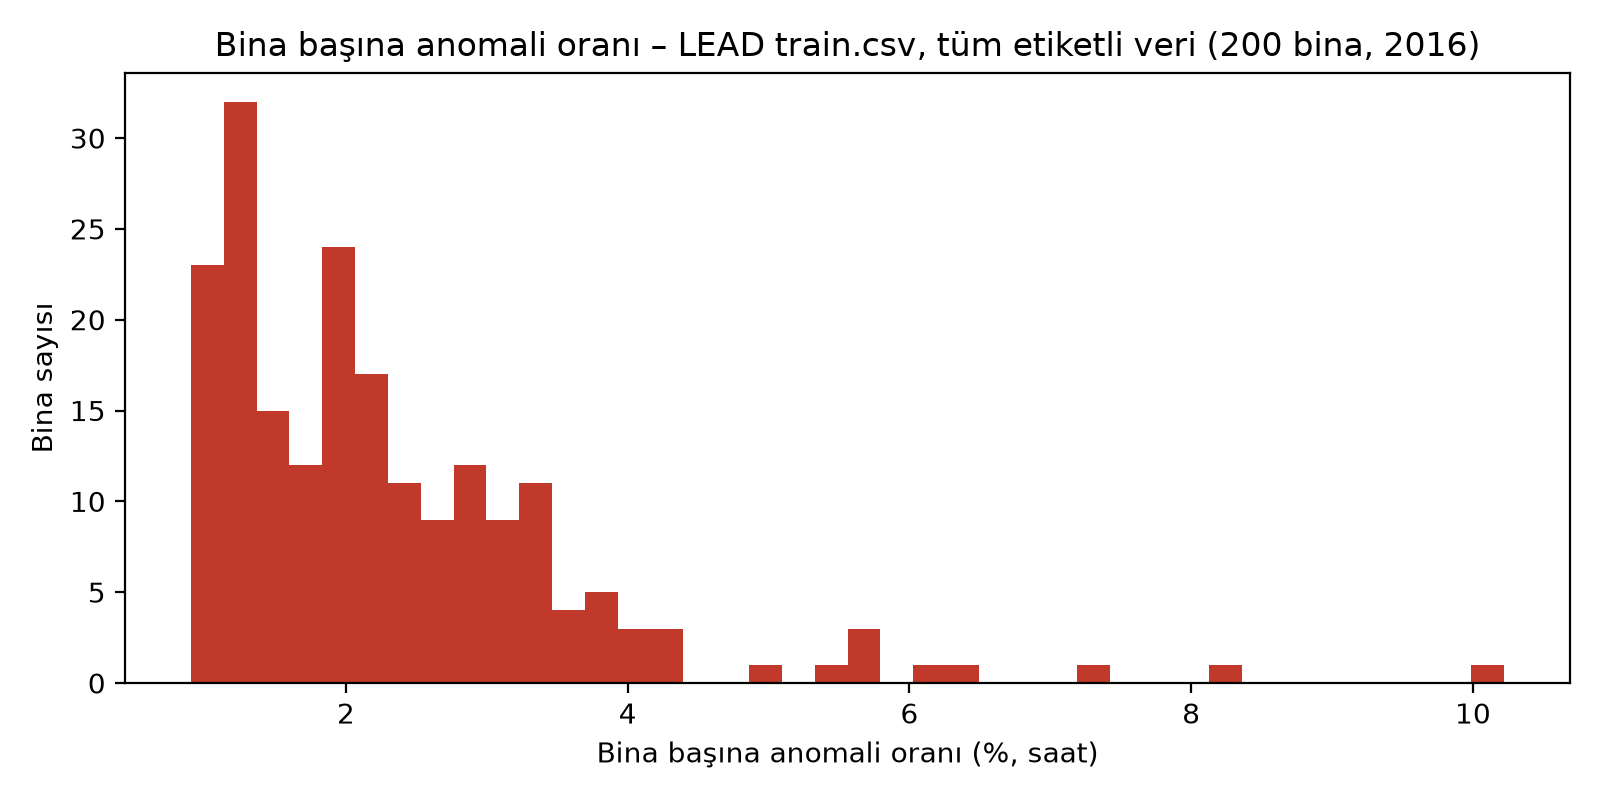

lead_building_scale.png


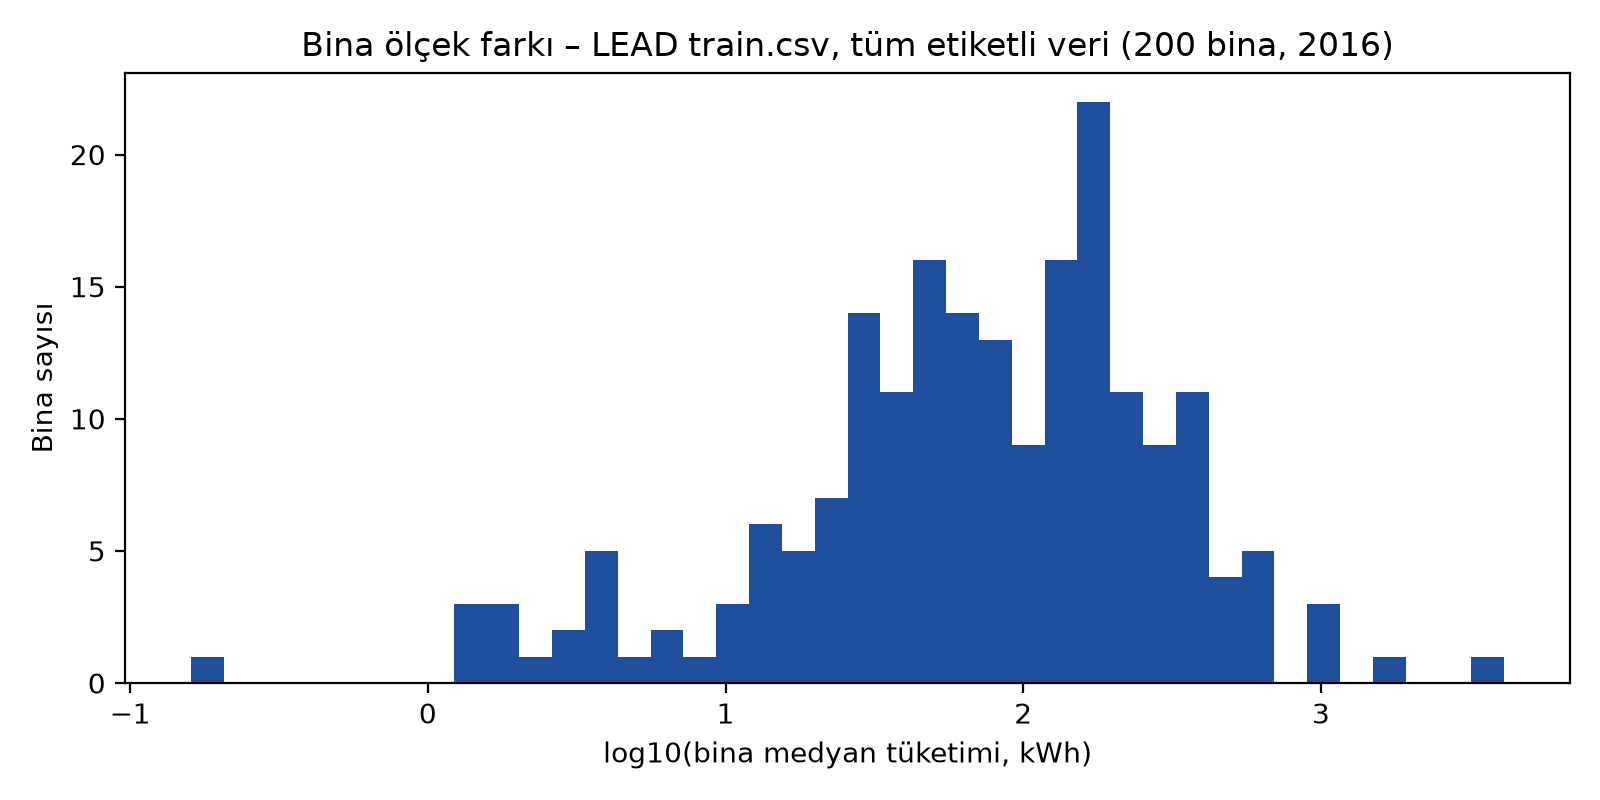

In [4]:
display(ctx.labels.loc[ctx.y == 1, "subtype"].value_counts(normalize=True).rename("anomali saatlerindeki pay").round(3))
figures = sorted((PROJECT_ROOT / "results" / "lead" / "figures").glob("*.png"))
print(len(figures), "kayıtlı EDA figürü")
for path in figures[:2]:
    print(path.name); display(Image(filename=str(path), width=700))

## 3. Bölme

Bina düzeyinde 120/40/40 (train/val/test), 3 seed (42, 7, 2026); bütün ölçek ve modeller yalnız train binalarına fit edildi. Siteye göre bölme yalnız val'de sağlamlık kontrolüydü.

In [5]:
splits = pd.read_csv(LEAD_TABLES / "splits.csv")
display(splits.groupby(["bolme", "seed", "parca"]).size().unstack("parca"))

parca       test  train  val
bolme seed                  
bina  7       40    120   40
      42      40    120   40
      2026    40    120   40
site  7       58     90   52
      42      62     68   70
      2026    69     82   49

## 4. Modeller

| kod | model | not |
|---|---|---|
| L0 | kurallar (R1 önceki saat eksik, R2 sabitlik, R3 = R1 ∨ R2) ve A0 hareketli z-skoru | eğitim yok |
| L1 | LightGBM (full / behavior) | Optuna, train CV |
| L1-FE | LightGBM + öznitelik grupları (her seed kendi seçimi, train CV) | §17 |
| L2 / L2-FE | GRU sınıflandırıcı (ana sinir ağı) | §8, §18 |
| L4 / L4-semi | Seq2Seq tahmin artığı (etiketsiz / etiketli anomaliler eğitimden çıkarılmış) | §8 |
| L5-FE | L1-FE + L2-FE topluluğu | ağırlık val'de |
| IF | Isolation Forest | yalnız literatür referansı |
| L1-OFF | L1-FE + iki yönlü (geleceğe bakan) öznitelikler | yalnız literatür kıyası; seçime girmez |

Eğitim komutları aşağıdaki hücrede yalnız `RUN_TRAINING = True` ise çalışır (varsayılan kapalı; test aşaması bu listede **yok**, o yalnız açık onayla çalıştırılır).

In [6]:
TRAINING_STAGES = ["l0", "l1", "l4", "deep --model L2", "fe", "l1fe", "l2fe", "l5fe", "if", "l1off", "improve", "summary"]
if RUN_TRAINING:
    import subprocess
    for stage in TRAINING_STAGES:
        subprocess.run(["python", "-m", "src.pipelines.lead_run", "--stage", *stage.split()], check=True, cwd=PROJECT_ROOT)
else:
    print("RUN_TRAINING = False: eğitim atlandı; kayıtlı skorlar kullanılacak.")

RUN_TRAINING = False: eğitim atlandı; kayıtlı skorlar kullanılacak.


## 5. Kayıtlı skorlarla değerlendirme (val ve test)

Her model × seed için kayıtlı skor dosyası okunur; `evaluate()` (`src/datasets/lead/evaluate.py`) **val'de seçilmiş eşikle** bütün dilimlerde ROC-AUC, PR-AUC, P/R/F1 ve olay recall'ü hesaplar. Sonuç kayıtlı `val_results.csv` / `test_results.csv` ile karşılaştırılır.

**Hassasiyet notu:** kayıtlı skor dosyaları yer kazanmak için **float32**'dir; kayıtlı metrikler ise kayıt anında float64 skorlarla hesaplandı. Bu yüzden (1) eşik de float32'ye yuvarlanır (eşik, skorlardan birinin kendisidir; yuvarlama onu eşiğin öbür yanına geçirmesin) — eşiğe bağlı metrikler (P/R/F1, olay recall) böylece **birebir** (tolerans 1e-6) karşılaştırılır; (2) sıralama metrikleri (ROC-AUC, PR-AUC) float32 yuvarlamasının yarattığı eşit skorlar yüzünden 1e-4 düzeyinde oynayabilir — tolerans **5e-4**. Bu fark sonuç değil, kayıt hassasiyetidir.

In [7]:
from src.datasets.lead.evaluate import evaluate
from src.pipelines.lead_test import FINAL_MODEL, TEST_MODELS

val_saved = pd.read_csv(LEAD_TABLES / "val_results.csv")
test_saved = pd.read_csv(LEAD_TABLES / "test_results.csv")
METRICS = ["roc_auc", "pr_auc", "precision", "recall", "f1", "event_recall"]

def rescore(part, saved):
    """Kayıtlı skorlar → dilim tablosu (val eşiğiyle). part: 'val' ya da 'test'."""
    rows = []
    for seed in config["split"]["seeds"]:
        split = ctx.split("bina", seed)
        mask = ctx.rows(split[part])
        labels = ctx.labels[mask].reset_index(drop=True)
        for model, fset in TEST_MODELS:
            prefix = "" if part == "val" else "test_"
            scores = np.load(SCORES / f"{prefix}bina_{seed}_{model}_{fset}.npy")
            threshold = float(saved[(saved.model == model) & (saved.set == fset) & (saved.bolme == "bina")
                                    & (saved.seed == seed)]["threshold"].iloc[0])
            table = evaluate(ctx.y[mask], scores, float(np.float32(threshold)), labels)   # float32 skorlarla tutarlı eşik
            rows += [{"model": model, "set": fset, "bolme": "bina", "seed": seed, **r} for r in table.to_dict("records")]
    return pd.DataFrame(rows)

val_new, test_new = rescore("val", val_saved), rescore("test", test_saved)
keys = ["model", "set", "bolme", "seed", "dilim"]
THRESHOLD_METRICS, RANK_METRICS, RANK_TOLERANCE = ["precision", "recall", "f1", "event_recall"], ["roc_auc", "pr_auc"], 5e-4
for name, new, saved in (("val_results.csv", val_new, val_saved), ("test_results.csv", test_new, test_saved)):
    compare_tables(f"LEAD {name}: eşiğe bağlı metrikler (birebir)", new, saved, keys, THRESHOLD_METRICS)
    compare_tables(f"LEAD {name}: ROC/PR-AUC (float32 bağları, tol {RANK_TOLERANCE})", new, saved, keys, RANK_METRICS,
                   tol=RANK_TOLERANCE)
print(len(val_new), "val satırı,", len(test_new), "test satırı yeniden hesaplandı")

234 val satırı, 234 test satırı yeniden hesaplandı


## 6. Sonuç tabloları ve figürler

3 seed ortalaması ± std; `other` ve genel dilimler, val ile test yan yana. Tam tablo (bütün dilimler ve metrikler) `docs/lead_sonuclar.md` §2'de.

In [8]:
def mean_std(table, dilim, column):
    part = table[table["dilim"] == dilim].groupby(["model", "set"])[column]
    return part.mean().round(3).astype(str) + " ± " + part.std().round(3).astype(str)

side = pd.DataFrame({"other PR-AUC val": mean_std(val_new, "other", "pr_auc"),
                     "other PR-AUC test": mean_std(test_new, "other", "pr_auc"),
                     "genel PR-AUC val": mean_std(val_new, "genel", "pr_auc"),
                     "genel PR-AUC test": mean_std(test_new, "genel", "pr_auc"),
                     "genel ROC-AUC test": mean_std(test_new, "genel", "roc_auc")})
display(side.loc[[m for m in TEST_MODELS if m in side.index]])

other PR-AUC val other PR-AUC test genel PR-AUC val genel PR-AUC test genel ROC-AUC test
model   set                                                                                              
L1      behavior    0.058 ± 0.011     0.051 ± 0.029    0.575 ± 0.017     0.646 ± 0.021      0.899 ± 0.008
L1-FE   full         0.053 ± 0.03      0.12 ± 0.009    0.667 ± 0.099     0.819 ± 0.023      0.954 ± 0.006
        behavior    0.055 ± 0.039     0.078 ± 0.049    0.572 ± 0.035     0.686 ± 0.078       0.915 ± 0.03
L0-R3   -           0.007 ± 0.002     0.005 ± 0.001    0.225 ± 0.154     0.398 ± 0.065      0.772 ± 0.009
L0-A0   -           0.057 ± 0.006     0.035 ± 0.017    0.361 ± 0.011     0.383 ± 0.029       0.735 ± 0.02
L4      -           0.055 ± 0.022     0.094 ± 0.014     0.14 ± 0.039     0.158 ± 0.004      0.593 ± 0.021
L4-semi -           0.048 ± 0.015      0.075 ± 0.03    0.431 ± 0.035      0.49 ± 0.038      0.727 ± 0.031
L2-FE   full        0.045 ± 0.019     0.109 ± 0.035    0.594 ± 0.086     0.768 ± 0.034      0.939 ± 0.007
        behavior    0.075 ± 0.062     0.106 ± 0.029    0.516 ± 0.086        0.65 ± 0.1       0.895 ± 0.04
L5-FE   full        0.053 ± 0.031     0.125 ± 0.017    0.668 ± 0.101     0.818 ± 0.025      0.956 ± 0.004
        behavior    0.074 ± 0.057     0.108 ± 0.042    0.583 ± 0.038     0.692 ± 0.084      0.923 ± 0.028
IF      behavior    0.012 ± 0.003     0.008 ± 0.004    0.089 ± 0.051       0.2 ± 0.185       0.762 ± 0.03
L1-OFF  full        0.057 ± 0.032      0.123 ± 0.02    0.707 ± 0.109     0.867 ± 0.034      0.972 ± 0.006

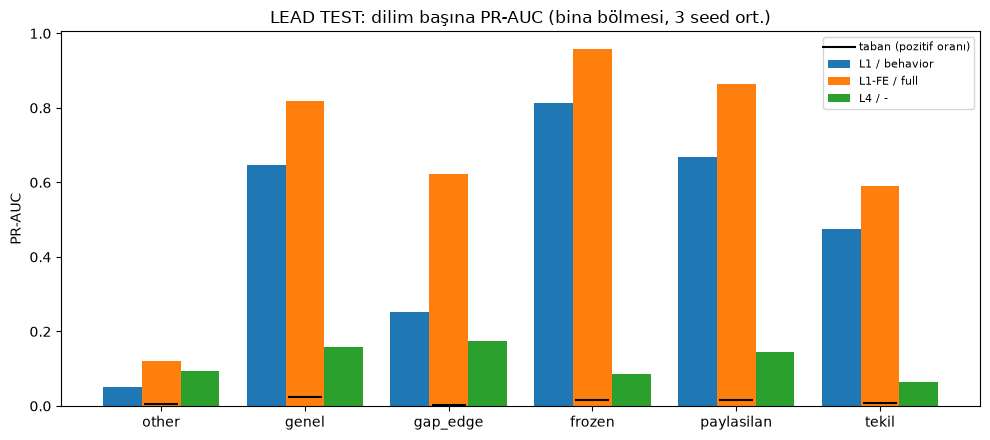

In [9]:
# Figür: dilim başına test PR-AUC (3 seed ort.), final model ve iki karşılaştırma; taban çizgili.
shown = [FINAL_MODEL, ("L1-FE", "full"), ("L4", "-")]
slices = ["other", "genel", "gap_edge", "frozen", "paylasilan", "tekil"]
figure, axis = plt.subplots(figsize=(10, 4.5))
width = 0.27
for i, (model, fset) in enumerate(shown):
    part = test_new[(test_new.model == model) & (test_new.set == fset)].groupby("dilim")["pr_auc"].mean()
    axis.bar(np.arange(len(slices)) + (i - 1) * width, [part[s] for s in slices], width, label=f"{model} / {fset}")
base = test_new.assign(taban=test_new.n_pos / (test_new.n_pos + test_new.n_neg)).groupby("dilim")["taban"].mean()
axis.scatter(np.arange(len(slices)), [base[s] for s in slices], marker="_", s=600, color="black", label="taban (pozitif oranı)")
axis.set_xticks(np.arange(len(slices)), slices)
axis.set(ylabel="PR-AUC", title="LEAD TEST: dilim başına PR-AUC (bina bölmesi, 3 seed ort.)")
axis.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Final model

Seçim **yalnız val**'de, önceden yazılmış kuralla yapıldı (`docs/lead_protokol.md` §18.2 ve §21): `other` PR-AUC → (gürültü düzeyindeyse) genel PR-AUC → (gürültüyse) sinir ağı **gerçekten katkı veriyorsa** tercih → basitlik sırası. Aşağıdaki hücre seçimi kayıtlı val sonuçlarından `select_model_v2` ile yeniden üretir ve kayıtlı seçim tablosuyla karşılaştırır.

In [10]:
from src.pipelines.lead_models import select_model_v2

selection = select_model_v2(val_saved)
chosen = selection[selection["secilen"]].iloc[0]
display(Markdown(f"**Final model: {chosen.model} / {chosen.set}** (val `other` PR-AUC {chosen.other_pr_auc:.3f}, genel PR-AUC {chosen.genel_pr_auc:.3f})"))
display(selection.round(4))
saved_selection = pd.read_csv(LEAD_TABLES / "val_selection_v2.csv")
compare_tables("LEAD val_selection_v2.csv (seçim yeniden üretimi)", selection, saved_selection, ["model", "set"],
               ["other_pr_auc", "genel_pr_auc", "other_fark", "other_2se"])
CHECKS.append({"kontrol": "seçilen model = kayıtlı seçim", "yeni_satir": 1, "eslesen": 1, "max_abs_fark": 0.0,
               "tamam": (chosen.model, chosen.set) == tuple(saved_selection[saved_selection.secilen][["model", "set"]].iloc[0])
                        and (chosen.model, chosen.set) == FINAL_MODEL})

**Final model: L1 / behavior** (val `other` PR-AUC 0.058, genel PR-AUC 0.575)

,model,set,other_pr_auc,genel_pr_auc,other_fark,other_2se,C1_other_gurultu,genel_fark,genel_2se,C2_genel_gurultu,sinir_agi,sinir_agi_katkisi,secilen
0,L2-FE,behavior,0.0746,0.5163,0.0000,0.0000,True,-0.1518,0.0386,False,True,True,False
1,L5-FE,behavior,0.0737,0.5830,-0.0009,0.0076,True,-0.0850,0.0744,False,True,True,False
2,L1,behavior,0.0582,0.5752,-0.0164,0.0808,True,-0.0929,0.0986,True,False,False,True
3,L0-A0,-,0.0568,0.3609,-0.0178,0.0793,True,-0.3072,0.1195,False,False,False,False
4,L1-FE,behavior,0.0546,0.5724,-0.0200,0.0273,True,-0.0957,0.0806,False,False,False,False
5,L4,-,0.0546,0.1401,-0.0200,0.0540,True,-0.5280,0.0772,False,True,True,False
6,L5-FE,full,0.0534,0.6681,-0.0212,0.0367,True,0.0000,0.0000,True,True,False,False
7,L1-FE,full,0.0529,0.6667,-0.0217,0.0376,True,-0.0014,0.0028,True,False,False,False
8,L1-I,full,0.0487,0.6403,-0.0258,0.0374,True,-0.0278,0.0364,True,False,False,False
9,L4-semi,-,0.0482,0.4311,-0.0264,0.0602,True,-0.2370,0.0791,False,True,True,False


## 8. Test sonrası gözlem

Test sonuçları görüldükten **sonra** yazıldı; final modeli değiştirmez (protokol §13). Metin ve tablolar `docs/lead_sonuclar.md` §7'den; aşağıdaki sayılar bu notebook'un yeniden hesapladığı tablolardan.

In [11]:
final_m, fe = FINAL_MODEL, ("L1-FE", "full")
for d in ("other", "genel"):
    print(f"{d} PR-AUC — test: final {final_m[0]}/{final_m[1]} {mean_std(test_new, d, 'pr_auc')[final_m]}, "
          f"L1-FE full {mean_std(test_new, d, 'pr_auc')[fe]}")
print("\nVal'de iki model gürültü düzeyindeydi; testte L1-FE full daha iyi genelleşti. Ders: tek val kümesi (seed başına "
      "40 bina) küçük farkları ayırt edemedi → gelecekte model seçimi bina bazlı (gruplu) çapraz doğrulamayla yapılmalı.")
composition = pd.read_csv(LEAD_TABLES / "test_split_composition.csv")
display(Markdown("**`other` skorları bina bileşimine çok duyarlı** — val ve test parçalarının bileşimi:"))
display(composition[composition.parca.isin(["val", "test"])][["seed", "parca", "other_taban", "frozen_pay", "other_pay",
                                                               "paylasilan_olay_pay", "other_ilk3_bina_pay"]].round(3))

other PR-AUC — test: final L1/behavior 0.051 ± 0.029, L1-FE full 0.12 ± 0.009
genel PR-AUC — test: final L1/behavior 0.646 ± 0.021, L1-FE full 0.819 ± 0.023

Val'de iki model gürültü düzeyindeydi; testte L1-FE full daha iyi genelleşti. Ders: tek val kümesi (seed başına 40 bina) küçük farkları ayırt edemedi → gelecekte model seçimi bina bazlı (gruplu) çapraz doğrulamayla yapılmalı.


**`other` skorları bina bileşimine çok duyarlı** — val ve test parçalarının bileşimi:

,seed,parca,other_taban,frozen_pay,other_pay,paylasilan_olay_pay,other_ilk3_bina_pay
1,42,val,0.009,0.477,0.407,0.625,0.371
2,42,test,0.005,0.689,0.188,0.720,0.347
4,7,val,0.006,0.665,0.215,0.744,0.282
5,7,test,0.006,0.609,0.268,0.707,0.388
7,2026,val,0.007,0.569,0.334,0.668,0.386
8,2026,test,0.004,0.669,0.182,0.769,0.319


## 9. Son kontrol: kayıtlı tablolarla birebir karşılaştırma ve `results/` değişmedi

In [12]:
snapshot_end = results_snapshot()
changed = sorted(k for k in set(SNAPSHOT_START) | set(snapshot_end) if SNAPSHOT_START.get(k) != snapshot_end.get(k))
CHECKS.append({"kontrol": "results/ altında değişen dosya yok", "yeni_satir": len(snapshot_end),
               "eslesen": len(snapshot_end) - len(changed), "max_abs_fark": float(len(changed)), "tamam": not changed})
report = pd.DataFrame(CHECKS)
display(report)
assert report["tamam"].all(), "Kayıtlı sonuçlarla fark var — yukarıdaki tabloya bakın."
print("Bütün kontroller geçti: notebook çıktıları kayıtlı LEAD tablolarıyla aynı; results/ değişmedi.")

,kontrol,yeni_satir,eslesen,max_abs_fark,tamam
0,LEAD val_results.csv: eşiğe bağlı metrikler (b...,234,234,1.110223e-16,True
1,LEAD val_results.csv: ROC/PR-AUC (float32 bağl...,234,234,1.327252e-04,True
2,LEAD test_results.csv: eşiğe bağlı metrikler (...,234,234,1.110223e-16,True
3,LEAD test_results.csv: ROC/PR-AUC (float32 bağ...,234,234,2.977053e-05,True
4,LEAD val_selection_v2.csv (seçim yeniden üretimi),19,19,9.714451e-17,True
5,seçilen model = kayıtlı seçim,1,1,0.000000e+00,True
6,results/ altında değişen dosya yok,826,826,0.000000e+00,True


Bütün kontroller geçti: notebook çıktıları kayıtlı LEAD tablolarıyla aynı; results/ değişmedi.
